In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import SpectralClustering
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

df = pd.read_excel('../data/data.xlsx')

df.head()

,Creativity,Intellectual Curiosity,Preference for Novelty,Openness to Diverse Cultures,Artistic Interests,Organizational Skills,Reliability,Punctuality,Attention to Detail,Work Ethic,...,Listening Skills,Conflict Resolution Abilities,Openness to Feedback,Expressiveness,Empathy in Communication,Political Views,Religious Beliefs,Cultural Values,Attitudes Towards Money and Finances,Views on Personal and Shared Spaces
0,4.0,1.0,5.0,2.0,5.0,1.0,5.0,2.0,4.0,1.0,...,5.0,1.0,4.0,1.0,4.0,1.0,5.0,3.0,4.0,5.0
1,3.0,5.0,3.0,4.0,3.0,3.0,2.0,5.0,1.0,5.0,...,1.0,2.0,4.0,2.0,3.0,1.0,4.0,2.0,5.0,3.0
2,2.0,3.0,4.0,4.0,3.0,2.0,1.0,3.0,2.0,5.0,...,5.0,1.0,2.0,1.0,4.0,2.0,5.0,3.0,4.0,4.0
3,2.0,2.0,2.0,3.0,4.0,2.0,2.0,4.0,1.0,4.0,...,4.0,2.0,5.0,2.0,3.0,1.0,4.0,4.0,3.0,3.0
4,3.0,3.0,3.0,3.0,5.0,3.0,3.0,5.0,3.0,4.0,...,5.0,1.0,5.0,1.0,5.0,1.0,5.0,3.0,5.0,5.0


In [ ]:
# general info of the dataset
print("Shape of dataset:", df.shape)

print("\nColumns in dataset:")
print(df.columns.tolist())

print("\nData types of each column:")
print(df.dtypes)

print("\nFirst few rows of dataset:")
print(df.head())

print("\nSummary statistics:")
print(df.describe())

print("\nChecking for missing values:")
print(df.isnull().sum())


Shape of dataset: (100000, 50)

Columns in dataset:
['Creativity', 'Intellectual Curiosity', 'Preference for Novelty', 'Openness to Diverse Cultures', 'Artistic Interests', 'Organizational Skills', 'Reliability', 'Punctuality', 'Attention to Detail', 'Work Ethic', 'Sociability', 'Energy Levels', 'Assertiveness', 'Talkativeness', 'Enthusiasm for Social Gatherings', 'Compassion', 'Cooperation', 'Trust in Others', 'Altruism', 'Modesty', 'Stress Management', 'Emotional Stability', 'Anxiety Levels', 'Mood Swings', 'Anger Management', 'Sleeping Patterns', 'Eating Habits', 'Cleanliness and Hygiene', 'Exercise Routines', 'Smoking and Drinking Habits', 'Music Preferences', 'Movie/TV Show Genres', 'Reading and Literature', 'Sports and Outdoor Activities', 'Cooking and Culinary Interests', 'Frequency of Hosting Guests', 'Participation in Community Events', 'Networking and Socializing Habits', 'Preference for Quiet vs. Lively Environment', 'Travel and Exploration Interests', 'Listening Skills', 'C

In [2]:
df = df.apply(lambda x: x.fillna(x.median()), axis=0)

# see if there is any missing value left
print(df.isnull().sum())

Creativity                                     0
Intellectual Curiosity                         0
Preference for Novelty                         0
Openness to Diverse Cultures                   0
Artistic Interests                             0
Organizational Skills                          0
Reliability                                    0
Punctuality                                    0
Attention to Detail                            0
Work Ethic                                     0
Sociability                                    0
Energy Levels                                  0
Assertiveness                                  0
Talkativeness                                  0
Enthusiasm for Social Gatherings               0
Compassion                                     0
Cooperation                                    0
Trust in Others                                0
Altruism                                       0
Modesty                                        0
Stress Management   

# Spectral Clustering
### (On 3000 samples)

The code below selects 3000 samples from the dataset and runs spectral clustering. A smaller sample was chosen because the full dataset is very large and the similarity matrix would be a 100000 x 100000 matrix and would need 72 GB of RAM.

In [ ]:
from sklearn.cluster import SpectralClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# choosing samples from 3000 data points
X_sample = df.sample(n=3000, random_state=42)

print("Testing different cluster numbers...")

for k in range(2, 6):
    spectral = SpectralClustering(n_clusters=k, affinity='nearest_neighbors', random_state=42)
    cluster_labels = spectral.fit_predict(X_sample)

    sil_score = silhouette_score(X_sample, cluster_labels)
    db_score = davies_bouldin_score(X_sample, cluster_labels)
    ch_score = calinski_harabasz_score(X_sample, cluster_labels)

    print(f"Clusters: {k}")
    print(f"  Silhouette Score:       {sil_score:.4f}")
    print(f"  Davies-Bouldin Index:   {db_score:.4f}  (lower is better)")
    print(f"  Calinski-Harabasz Score:{ch_score:.2f}  (higher is better)\n")


Testing different cluster numbers...
Clusters: 2
  Silhouette Score:       0.5100
  Davies-Bouldin Index:   0.6879  (lower is better)
  Calinski-Harabasz Score:70.39  (higher is better)

Clusters: 3
  Silhouette Score:       0.1471
  Davies-Bouldin Index:   1.6025  (lower is better)
  Calinski-Harabasz Score:94.32  (higher is better)

Clusters: 4
  Silhouette Score:       0.1062
  Davies-Bouldin Index:   1.9901  (lower is better)
  Calinski-Harabasz Score:198.54  (higher is better)

Clusters: 5
  Silhouette Score:       0.0817
  Davies-Bouldin Index:   2.1326  (lower is better)
  Calinski-Harabasz Score:194.30  (higher is better)



### Describing the output
The metrics used to evaluate the clustering model is these three:
- Silhouette score: Is between -1 and 1 and shows how close each data point is to its own cluster and how far it is from other clusters. 

- Davis-Bouldin Index (DBI): This metric is the mean of the distance between clusters in proportion to their inner diagonal. It's usually between 0.5 to 3. The lower the better.

- Calinski-Harabasz Index (CH): Doesn't have a range. The higher the better. It shows the variance between clusters relative to the variance inside the clusters. 

The last metric is better for k = 4 but when we put it next to other metrics it's not doing very well. 
The best scores belong to k = 2 but overall the scores show that maybe the clusters are not that seperate from each other. We see this especially when the number of clusters rise. 



# Spectral Clustering 
### (With combined features)

In [ ]:
from sklearn.cluster import SpectralClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Constructing combined features
df_combined = pd.DataFrame()
df_combined['Social_Score'] = df[['Trust in Others', 'Cooperation', 'Compassion', 'Altruism']].mean(axis=1)
df_combined['Intellectual_Cultural_Score'] = df[['Artistic Interests', 'Preference for Novelty', 'Intellectual Curiosity', 'Openness to Diverse Cultures']].mean(axis=1)
df_combined['Personal_Character_Score'] = df[['Reliability', 'Modesty']].mean(axis=1)

# scaling and sampling 
df_combined_sample = df_combined.sample(n=3000, random_state=42)
X_scaled = StandardScaler().fit_transform(df_combined_sample)

for k in range(2, 6):
    spectral = SpectralClustering(n_clusters=k, affinity='rbf', gamma=1.0, random_state=42)
    cluster_labels = spectral.fit_predict(X_scaled)

    sil_score = silhouette_score(X_scaled, cluster_labels)
    db_score = davies_bouldin_score(X_scaled, cluster_labels)
    ch_score = calinski_harabasz_score(X_scaled, cluster_labels)

    print(f"Clusters: {k}")
    print(f"  Silhouette Score:       {sil_score:.4f}")
    print(f"  Davies-Bouldin Index:   {db_score:.4f}  (lower is better)")
    print(f"  Calinski-Harabasz Score:{ch_score:.2f}  (higher is better)\n")


Clusters: 2
  Silhouette Score:       0.7131
  Davies-Bouldin Index:   0.2254  (lower is better)
  Calinski-Harabasz Score:140.67  (higher is better)

Clusters: 3
  Silhouette Score:       0.6402
  Davies-Bouldin Index:   0.2447  (lower is better)
  Calinski-Harabasz Score:77.04  (higher is better)

Clusters: 4
  Silhouette Score:       0.5770
  Davies-Bouldin Index:   0.8116  (lower is better)
  Calinski-Harabasz Score:57.02  (higher is better)

Clusters: 5
  Silhouette Score:       0.4458
  Davies-Bouldin Index:   0.8696  (lower is better)
  Calinski-Harabasz Score:46.65  (higher is better)



### About the output
We see that combining features gave generally better results.

# DBSCAN 
### (only on important features)

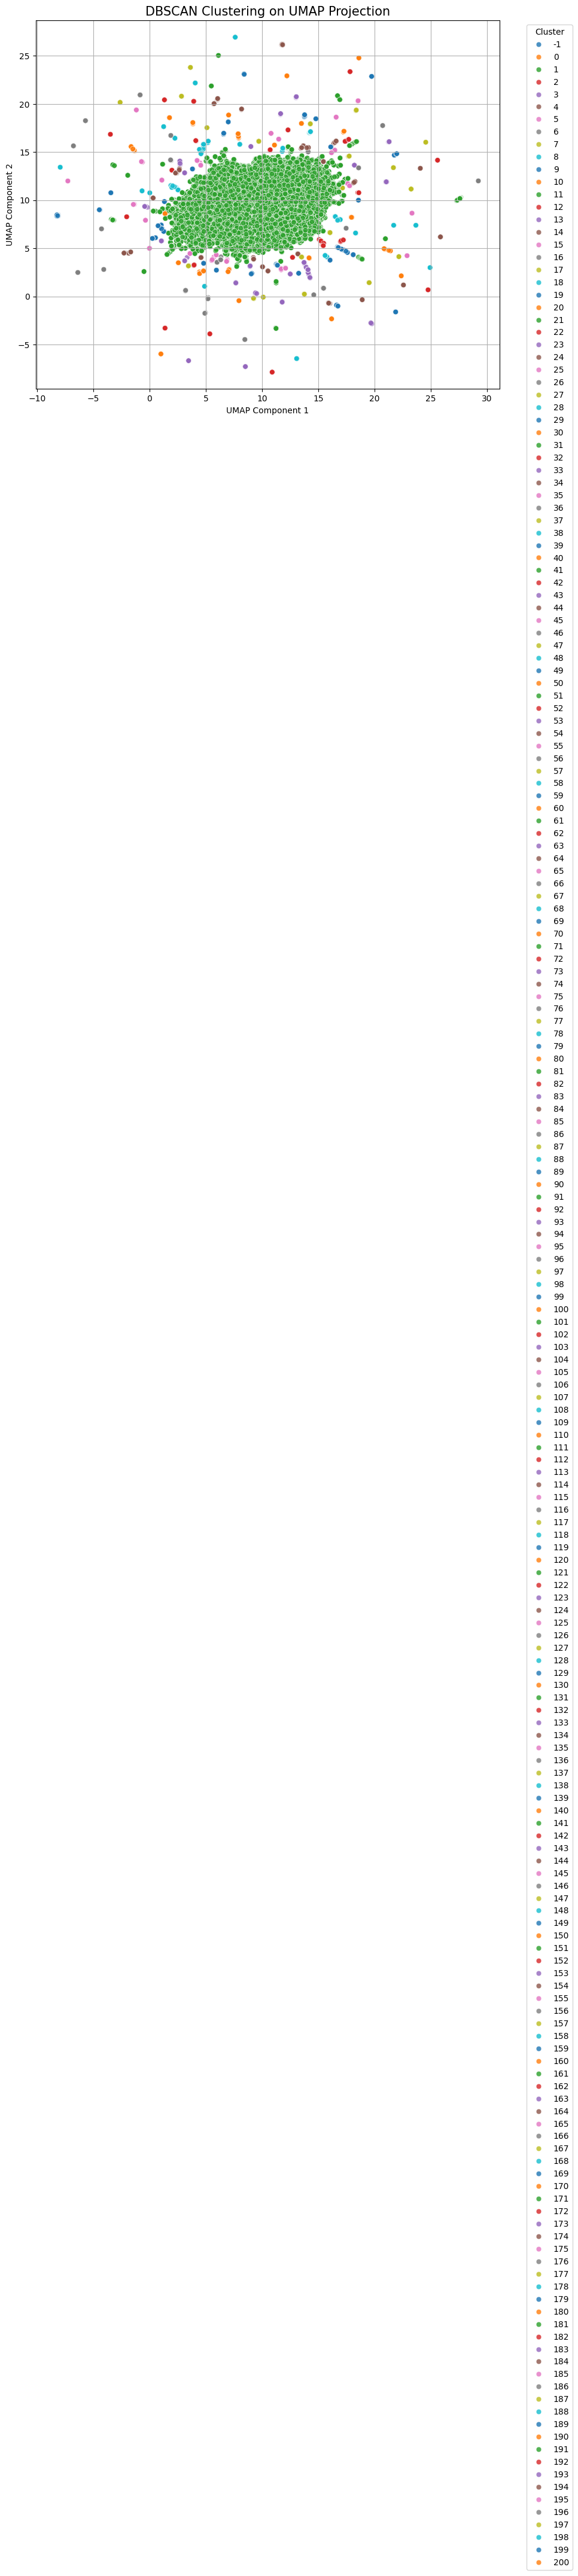

number of data points in each cluster:
-1         43
 0         18
 1      92945
 2         33
 3         17
        ...  
 196       23
 197       17
 198       14
 199       18
 200       12
Length: 202, dtype: int64

 number of clusters, DBSCAN: 201
Noise: 43


In [ ]:
from sklearn.cluster import DBSCAN

X_umap = df[['UMAP Component 1', 'UMAP Component 2']].values

dbscan = DBSCAN(eps=0.4, min_samples=10)  
dbscan_labels = dbscan.fit_predict(X_umap)

df['DBSCAN Cluster'] = dbscan_labels

plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='UMAP Component 1', y='UMAP Component 2',
    hue='DBSCAN Cluster', data=df,
    palette='tab10', s=40, alpha=0.8
)
plt.title('DBSCAN Clustering on UMAP Projection', fontsize=15)
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.show()

from collections import Counter

cluster_counts = Counter(dbscan_labels)
num_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
num_noise = list(dbscan_labels).count(-1)

print("Number of data points in each cluster:")
print(pd.Series(cluster_counts).sort_index())
print(f"\n number of clusters: {num_clusters}")
print(f"Noise: {num_noise}")


# DBSCAN 
### (on all the features)

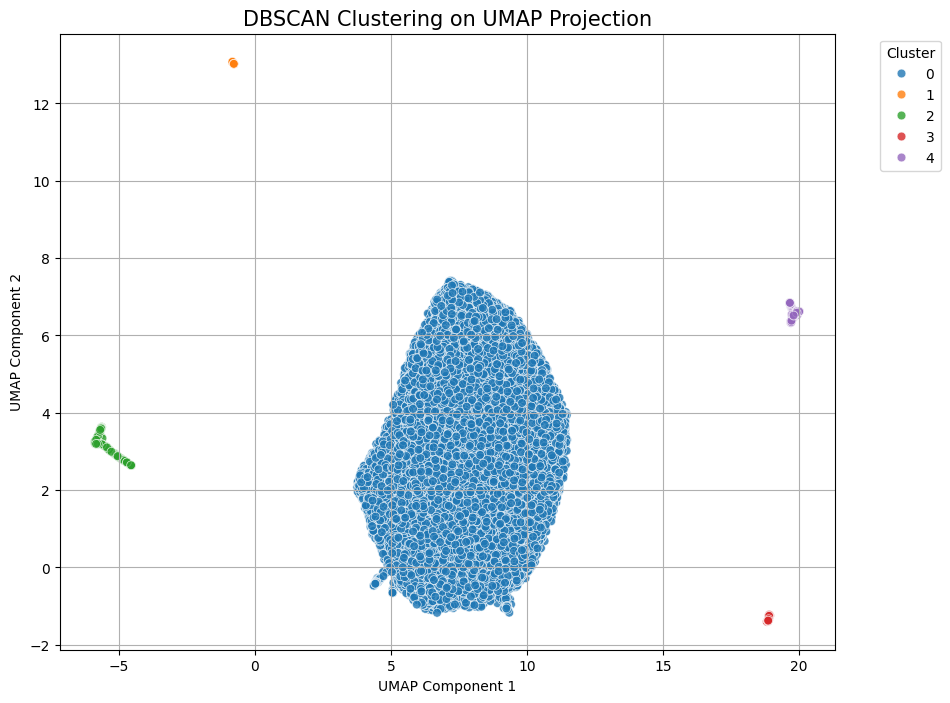

Number of data points in each cluster:
0    99358
1       87
2      241
3       98
4      216
dtype: int64

 number of clusters: 5
Noise: 0


In [7]:
from sklearn.cluster import DBSCAN

X_umap = df[['UMAP Component 1', 'UMAP Component 2']].values

dbscan = DBSCAN(eps=0.4, min_samples=10) 
dbscan_labels = dbscan.fit_predict(X_umap)

df['DBSCAN Cluster'] = dbscan_labels

plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='UMAP Component 1', y='UMAP Component 2',
    hue='DBSCAN Cluster', data=df,
    palette='tab10', s=40, alpha=0.8
)
plt.title('DBSCAN Clustering on UMAP Projection', fontsize=15)
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.show()

from collections import Counter

cluster_counts = Counter(dbscan_labels)
num_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
num_noise = list(dbscan_labels).count(-1)

print("Number of data points in each cluster:")
print(pd.Series(cluster_counts).sort_index())
print(f"\n number of clusters: {num_clusters}")
print(f"Noise: {num_noise}")



### Evaluating the model

In [8]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Removing noise points
mask = dbscan_labels != -1
X_clustered = X_umap[mask]
labels_clustered = dbscan_labels[mask]

# Calculating clustering metrics
sil_score = silhouette_score(X_clustered, labels_clustered)
db_score = davies_bouldin_score(X_clustered, labels_clustered)
ch_score = calinski_harabasz_score(X_clustered, labels_clustered)

print(f"Silhouette Score:       {sil_score:.4f}")
print(f"Davies-Bouldin Index:   {db_score:.4f}  (lower is better)")
print(f"Calinski-Harabasz Score:{ch_score:.2f}  (higher is better)")


Silhouette Score:       0.6900
Davies-Bouldin Index:   0.2094  (lower is better)
Calinski-Harabasz Score:3871.81  (higher is better)


# KMeans on each category of features
There are 50 features in the dataset. These features can be categorized in 7 different groups. In the code cell below KMeans is applied to the features of each category, separately. The result is then evaluated by the three metrics. 


### The categories: 

#### 1. Lifestyle: 
- Sleeping Patterns
- Eating Habits
- Exercise Routines
- Cleanliness and Hygiene
- Smoking and Drinking Habits
- Attitudes Towards Money and Finances
- Preference for Quiet vs. Lively Environment
- Views on Personal and Shared Spaces

#### 2. Interests & Activities: 
- Music Preferences
- Movie/TV Show Genres
- Reading and Literature
- Sports and Outdoor Activities
- Cooking and Culinary Interests
- Travel and Exploration Interests
- Artistic Interests
- Creativity

#### 3. Communication & Interaction
- Listening Skills
- Conflict Resolution Abilities
- Openness to Feedback
- Expressiveness
- Empathy in Communication
- Frequency of Hosting Guests
- Participation in Community Events
- Networking and Socializing Habits

#### 4. Responsibility & Organization
- Work Ethic
- Organizational Skills
- Reliability
- Punctuality
- Attention to Detail

#### 5. Social Engagement & Behavior
- Talkativeness
- Enthusiasm for Social Gatherings
- Energy Levels
- Sociability
- Assertiveness
- Cooperation
- Trust in Others
- Altruism
- Modesty

#### 6. Emotional Regulation & Stability
- Compassion
- Anger Management
- Stress Management
- Emotional Stability
- Anxiety Levels
- Mood Swings

#### 7. Openness & Core Beliefs
- Intellectual Curiosity
- Preference for Novelty
- Openness to Diverse Cultures
- Political Views
- Religious Beliefs
- Cultural Values

## KMeans on Lifestyle category

In [3]:
lifestyle_columns = [
    'Sleeping Patterns',
    'Eating Habits',
    'Exercise Routines',
    'Cleanliness and Hygiene',
    'Attitudes Towards Money and Finances',
    'Preference for Quiet vs. Lively Environment',
    'Views on Personal and Shared Spaces'
]
# Extracting lifestyle features
X_lifestyle = df[lifestyle_columns]

In [4]:
from sklearn.preprocessing import StandardScaler

# Scaling the lifestyle features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_lifestyle)

In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from collections import Counter

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    counts = Counter(labels)

    sil = silhouette_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)
    ch = calinski_harabasz_score(X_scaled, labels)

    print(f'Clusters: {k}')
    print(f'  Silhouette Score:       {sil:.4f}')
    print(f'  Davies-Bouldin Index:   {db:.4f}')
    print(f'  Calinski-Harabasz Score:{ch:.2f}')
    print(f"  Cluster counts: {dict(counts)}")
    print('---')

c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\Python311\Lib\subprocess.py", line 1024, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Program Files\Python311\Lib\subprocess.py", line 1509, in _execute_child
  

Clusters: 2
  Silhouette Score:       0.2209
  Davies-Bouldin Index:   1.8275
  Calinski-Harabasz Score:26009.16
  Cluster counts: {np.int32(1): 63968, np.int32(0): 36032}
---
Clusters: 3
  Silhouette Score:       0.1412
  Davies-Bouldin Index:   2.1004
  Calinski-Harabasz Score:18901.18
  Cluster counts: {np.int32(1): 44506, np.int32(2): 31243, np.int32(0): 24251}
---
Clusters: 4
  Silhouette Score:       0.1279
  Davies-Bouldin Index:   2.0587
  Calinski-Harabasz Score:16027.17
  Cluster counts: {np.int32(1): 29501, np.int32(3): 33240, np.int32(2): 22750, np.int32(0): 14509}
---
Clusters: 5
  Silhouette Score:       0.1288
  Davies-Bouldin Index:   1.8648
  Calinski-Harabasz Score:15071.50
  Cluster counts: {np.int32(3): 27315, np.int32(2): 20916, np.int32(0): 9742, np.int32(1): 23606, np.int32(4): 18421}
---
Clusters: 6
  Silhouette Score:       0.1276
  Davies-Bouldin Index:   1.7956
  Calinski-Harabasz Score:13712.49
  Cluster counts: {np.int32(4): 14117, np.int32(2): 19398, np.in

### output analyzation
- k = 2 has the best Silhouette and CH scores and one of the lowest DBI values. However 64% of the data falls into a single cluster. (imbalanced clusters)
- k = 3, 4, 5: The scores generally decrease, but the clusters become more balanced in size. DBI is better in k = 5 rather than k = 3 and 4.
- k = 6, 7, 8: Silhouette and CH scores continue to drop, but DBI improves. k = 8 has the lowest DBI that shows better seperation between clusters. But cluster 0 contains only 620 samples and might be an outlier group. 
- k = 9, 10: No significant improvement in the scores. There are a few clusters with less than 600 samples in them that can show overclustering. 

## KMeans on Interest & Activities Category

In [9]:
interest_columns = [
    'Music Preferences',
    "Movie/TV Show Genres",
    "Reading and Literature",
    "Sports and Outdoor Activities",
    "Cooking and Culinary Interests",
    "Travel and Exploration Interests",
    "Artistic Interests",
    "Creativity"
]
# Extracting interest features
X_interest = df[interest_columns]

In [10]:
from sklearn.preprocessing import StandardScaler

# Scaling the lifestyle features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_interest)

In [11]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from collections import Counter

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    counts = Counter(labels)

    sil = silhouette_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)
    ch = calinski_harabasz_score(X_scaled, labels)

    print(f'Clusters: {k}')
    print(f'  Silhouette Score:       {sil:.4f}')
    print(f'  Davies-Bouldin Index:   {db:.4f}')
    print(f'  Calinski-Harabasz Score:{ch:.2f}')
    print(f"  Cluster counts: {dict(counts)}")
    print('---')

Clusters: 2
  Silhouette Score:       0.1789
  Davies-Bouldin Index:   1.9228
  Calinski-Harabasz Score:24685.50
  Cluster counts: {np.int32(1): 50465, np.int32(0): 49535}
---
Clusters: 3
  Silhouette Score:       0.1526
  Davies-Bouldin Index:   1.9810
  Calinski-Harabasz Score:19358.23
  Cluster counts: {np.int32(1): 32142, np.int32(0): 37987, np.int32(2): 29871}
---
Clusters: 4
  Silhouette Score:       0.1297
  Davies-Bouldin Index:   1.9831
  Calinski-Harabasz Score:16481.88
  Cluster counts: {np.int32(1): 29166, np.int32(3): 26275, np.int32(2): 20164, np.int32(0): 24395}
---
Clusters: 5
  Silhouette Score:       0.1203
  Davies-Bouldin Index:   1.9816
  Calinski-Harabasz Score:14535.55
  Cluster counts: {np.int32(1): 24234, np.int32(0): 22668, np.int32(3): 14808, np.int32(2): 17668, np.int32(4): 20622}
---
Clusters: 6
  Silhouette Score:       0.1145
  Davies-Bouldin Index:   1.9259
  Calinski-Harabasz Score:12920.89
  Cluster counts: {np.int32(1): 18795, np.int32(3): 17098, np.i

### Output Analyzation

- The highest Silhouette score belongs to k = 2 which is 0.1789. After that we see this score decreasing and at k = 5 it roughly stays the same.
- The best DBI score belongs to k = 2 which is 1.922. It does change with different k values but the different values are not that much different from each other. So there's not much improvement. 
- The highest score for CH belongs to k = 2 which is 24685. It decreases over time and we see drastic decrease after k = 5.


- k = 2, 3 -> good balance between cluster members
- k = 4, 5 -> weaker balance between clusters but still acceptable
- k = 6, 7, 8, 9, 10 -> High difference between clusters, imbalance


## KMeans on Communication & Interaction Category

In [4]:
communication_columns = [
    "Listening Skills",
    "Conflict Resolution Abilities",
    "Openness to Feedback",
    "Expressiveness",
    "Empathy in Communication",
    "Frequency of Hosting Guests",
    "Participation in Community Events",
    "Networking and Socializing Habits"
]

X_communication = df[communication_columns]

In [5]:
from sklearn.preprocessing import StandardScaler

# Scaling the communication features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_communication)

In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from collections import Counter

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    counts = Counter(labels)

    sil = silhouette_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)
    ch = calinski_harabasz_score(X_scaled, labels)

    print(f'Clusters: {k}')
    print(f'  Silhouette Score:       {sil:.4f}')
    print(f'  Davies-Bouldin Index:   {db:.4f}')
    print(f'  Calinski-Harabasz Score:{ch:.2f}')
    print(f"  Cluster counts: {dict(counts)}")
    print('---')

Clusters: 2
  Silhouette Score:       0.1724
  Davies-Bouldin Index:   2.0941
  Calinski-Harabasz Score:20445.82
  Cluster counts: {np.int32(0): 57343, np.int32(1): 42657}
---
Clusters: 3
  Silhouette Score:       0.1349
  Davies-Bouldin Index:   1.9142
  Calinski-Harabasz Score:17382.87
  Cluster counts: {np.int32(2): 34585, np.int32(0): 33359, np.int32(1): 32056}
---
Clusters: 4
  Silhouette Score:       0.1294
  Davies-Bouldin Index:   2.0831
  Calinski-Harabasz Score:14772.87
  Cluster counts: {np.int32(2): 30708, np.int32(0): 18510, np.int32(1): 28238, np.int32(3): 22544}
---
Clusters: 5
  Silhouette Score:       0.1214
  Davies-Bouldin Index:   2.0212
  Calinski-Harabasz Score:12877.24
  Cluster counts: {np.int32(4): 28527, np.int32(2): 14325, np.int32(1): 24364, np.int32(0): 15790, np.int32(3): 16994}
---
Clusters: 6
  Silhouette Score:       0.1184
  Davies-Bouldin Index:   2.0060
  Calinski-Harabasz Score:11445.06
  Cluster counts: {np.int32(1): 23837, np.int32(5): 13829, np.i

### Output Analyzation

- k = 2: It has the highest Silhouette and CH score with okay enough DBI. This indicates distinct clusters that are well-separated. Cluster sizes are fairly balanced. 
- k = 3, 4: Silhouette score drops which shows more data points are near decision boundaries. Clusters sizes are still acceptable but separation worsens. 
- K = 5-10: We see sharp drop in Silhouette and CH scores. Clusters are small and overlapping. DbI remains high, indicating poor cluster distinctiveness. Many clusters contain less than 10% of the data and are imbalanced. 

## KMeans on Responsibility & Organization Category 

In [7]:
responsibility_columns = [
    "Work Ethic",
    "Organizational Skills",
    "Reliability",
    "Punctuality",
    "Attention to Detail"
]

X_responsibility = df[responsibility_columns]

In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_responsibility)

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from collections import Counter

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    counts = Counter(labels)

    sil = silhouette_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)
    ch = calinski_harabasz_score(X_scaled, labels)

    print(f'Clusters: {k}')
    print(f'  Silhouette Score:       {sil:.4f}')
    print(f'  Davies-Bouldin Index:   {db:.4f}')
    print(f'  Calinski-Harabasz Score:{ch:.2f}')
    print(f"  Cluster counts: {dict(counts)}")
    print('---')

Clusters: 2
  Silhouette Score:       0.3003
  Davies-Bouldin Index:   1.2848
  Calinski-Harabasz Score:53316.93
  Cluster counts: {np.int32(1): 48032, np.int32(0): 51968}
---
Clusters: 3
  Silhouette Score:       0.2135
  Davies-Bouldin Index:   1.5867
  Calinski-Harabasz Score:38808.55
  Cluster counts: {np.int32(1): 26963, np.int32(0): 31399, np.int32(2): 41638}
---
Clusters: 4
  Silhouette Score:       0.2211
  Davies-Bouldin Index:   1.6119
  Calinski-Harabasz Score:32602.79
  Cluster counts: {np.int32(1): 23604, np.int32(0): 28125, np.int32(2): 22483, np.int32(3): 25788}
---
Clusters: 5
  Silhouette Score:       0.2017
  Davies-Bouldin Index:   1.5597
  Calinski-Harabasz Score:29600.88
  Cluster counts: {np.int32(1): 19879, np.int32(3): 20506, np.int32(4): 24458, np.int32(0): 16897, np.int32(2): 18260}
---
Clusters: 6
  Silhouette Score:       0.2072
  Davies-Bouldin Index:   1.5189
  Calinski-Harabasz Score:27199.94
  Cluster counts: {np.int32(1): 18852, np.int32(5): 18623, np.i

### Output Analyzation
- Silhouette score trend: This score peaks at 2 clusters at 0.3003 which shows a fairly well-defined clustering structure. But as the number of clusters increases the silhouette score consistently drops for k = 3 to 10 (0.20 - 0.22). This indicated that the more clusters we have the more blury distinctions we have. Adding more clusters does not significantly improve the clustering.
- DBI trend: (lower values are better). This metric starts at 1.28 for 2 clusters which indicated well-separated clusters. The index increases sharply to 1.5 and 1.6 at 3 and 4 clusters implying increased similarity between cluster centroids. But from k=5, DBI shows gradual and consistent decline dropping to 1.39 at 10 clusters. This suggests that adding clusters doesn't imporve silhouette socre but it does make separation better, especially after k = 6. 
- CH trend: This is at highest at 53,316.93 for2 clusters and drops significantly to 38,808.55 at 3 clusters and then continues to decline. This is expected. Despite the drop scores remain reasonably high with 21,695.91 at 10 clusters showing that the internal compactness remains high. 

2 clusters -> the best result

More clusters -> the groups become less clear and more mixed 

But still, from around 5 clusers and up there are small improvements in how separated the groups are which could mean there are some weaker sub-groups in the data. 


## KMeans on Social Engagement & Behavior Category

In [4]:
Social_columns = [
    "Talkativeness",
    "Enthusiasm for Social Gatherings",
    "Energy Levels",
    "Sociability",
    "Assertiveness",
    "Cooperation",
    "Trust in Others",
    "Altruism",
    "Modesty"
]

X_Social = df[Social_columns]

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_Social)

In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from collections import Counter

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    counts = Counter(labels)

    sil = silhouette_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)
    ch = calinski_harabasz_score(X_scaled, labels)

    print(f'Clusters: {k}')
    print(f'  Silhouette Score:       {sil:.4f}')
    print(f'  Davies-Bouldin Index:   {db:.4f}')
    print(f'  Calinski-Harabasz Score:{ch:.2f}')
    print(f"  Cluster counts: {dict(counts)}")
    print('---')

Clusters: 2
  Silhouette Score:       0.2491
  Davies-Bouldin Index:   1.4810
  Calinski-Harabasz Score:41596.50
  Cluster counts: {np.int32(0): 47965, np.int32(1): 52035}
---
Clusters: 3
  Silhouette Score:       0.1619
  Davies-Bouldin Index:   1.8670
  Calinski-Harabasz Score:29295.10
  Cluster counts: {np.int32(2): 25704, np.int32(0): 41961, np.int32(1): 32335}
---
Clusters: 4
  Silhouette Score:       0.1532
  Davies-Bouldin Index:   2.0425
  Calinski-Harabasz Score:23255.69
  Cluster counts: {np.int32(2): 23716, np.int32(0): 27285, np.int32(3): 21922, np.int32(1): 27077}
---
Clusters: 5
  Silhouette Score:       0.1259
  Davies-Bouldin Index:   2.0710
  Calinski-Harabasz Score:19578.65
  Cluster counts: {np.int32(2): 22618, np.int32(0): 20363, np.int32(3): 20414, np.int32(4): 14886, np.int32(1): 21719}
---
Clusters: 6
  Silhouette Score:       0.1205
  Davies-Bouldin Index:   1.9798
  Calinski-Harabasz Score:17271.95
  Cluster counts: {np.int32(2): 20264, np.int32(0): 17753, np.i

### Output Analyzation
- The silhouette score is highest when using 2 clusters 0.2491 showing the best separation between groups. As we add more clusters the score quickly drops and stays low. This shows that extra clusters don't form clear and well-separated groups.

- The lowest (best) DBI score is also at 2 clusters: 1.481 which means the clusters are more compact and distinct there. As the number of clusetrs increases the DBI gets worse especially around 3 to 5 clusters. It slightly improves after that but not by much. 4

- The highest CH score is at 2 clusters showing strong group separation. Just like the other metrics the CH score steadily drops as we add more clusters suggesting that the data becomes more scattered and less structured. 

- Overall the best clustering happens at k = 2 where all three metrics are at their best. More clusters don't help and actually make the groups less clear. 

## KMeans on Emotional Regulation & Stability Category


In [3]:
stability_columns = [
    'Compassion',
    'Anger Management',
    'Stress Management',
    'Emotional Stability',
    'Anxiety Levels',
    'Mood Swings'
]

X_stability = df[stability_columns]

In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_stability)

In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from collections import Counter

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    counts = Counter(labels)

    sil = silhouette_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)
    ch = calinski_harabasz_score(X_scaled, labels)

    print(f'Clusters: {k}')
    print(f'  Silhouette Score:       {sil:.4f}')
    print(f'  Davies-Bouldin Index:   {db:.4f}')
    print(f'  Calinski-Harabasz Score:{ch:.2f}')
    print(f"  Cluster counts: {dict(counts)}")
    print('---')

Clusters: 2
  Silhouette Score:       0.2497
  Davies-Bouldin Index:   1.6504
  Calinski-Harabasz Score:32228.81
  Cluster counts: {np.int32(1): 63208, np.int32(0): 36792}
---
Clusters: 3
  Silhouette Score:       0.1680
  Davies-Bouldin Index:   1.7724
  Calinski-Harabasz Score:24660.01
  Cluster counts: {np.int32(1): 36688, np.int32(0): 28960, np.int32(2): 34352}
---
Clusters: 4
  Silhouette Score:       0.1735
  Davies-Bouldin Index:   1.7147
  Calinski-Harabasz Score:21673.71
  Cluster counts: {np.int32(1): 31797, np.int32(0): 23848, np.int32(2): 28098, np.int32(3): 16257}
---
Clusters: 5
  Silhouette Score:       0.1549
  Davies-Bouldin Index:   1.7005
  Calinski-Harabasz Score:19223.78
  Cluster counts: {np.int32(1): 20987, np.int32(4): 21197, np.int32(3): 20904, np.int32(0): 13290, np.int32(2): 23622}
---
Clusters: 6
  Silhouette Score:       0.1667
  Davies-Bouldin Index:   1.5747
  Calinski-Harabasz Score:18826.03
  Cluster counts: {np.int32(1): 18996, np.int32(5): 18800, np.i

### Output Analyzation
- The best silhouette score is at 2 clusters (0.2497), showing the clearest separation. When more clusters are added, the score drops and stays lower, meaning the new groups are not as distinct.

- The lowest DBI is at 6 clusters (1.5747), slightly better than at 2. This suggests that while 2 clusters are cleanest overall, 6 clusters might still form reasonably compact and distinct subgroups.

- The highest CH score is again at 2 clusters (32228.81). This confirms that splitting the data into two main groups gives the strongest structure. The score gradually declines with more clusters, though the drop is smoother than in some other categories.

- 2 clusters offer the clearest and most distinct split for this category. However, metrics suggest that 6 clusters could still carry some meaningful structure. Even so, these smaller clusters are less clearly separated than the two main groups.

## KMeans on Openness & Core Beliefs

In [6]:
openness_columns = [
    'Intellectual Curiosity',
    'Preference for Novelty',
    'Openness to Diverse Cultures',
    'Political Views',
    'Religious Beliefs',
    'Cultural Values'
]

X_openness = df[openness_columns]

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_openness)

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from collections import Counter

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    counts = Counter(labels)

    sil = silhouette_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)
    ch = calinski_harabasz_score(X_scaled, labels)

    print(f'Clusters: {k}')
    print(f'  Silhouette Score:       {sil:.4f}')
    print(f'  Davies-Bouldin Index:   {db:.4f}')
    print(f'  Calinski-Harabasz Score:{ch:.2f}')
    print(f"  Cluster counts: {dict(counts)}")
    print('---')

Clusters: 2
  Silhouette Score:       0.2097
  Davies-Bouldin Index:   1.7388
  Calinski-Harabasz Score:28999.39
  Cluster counts: {np.int32(1): 47644, np.int32(0): 52356}
---
Clusters: 3
  Silhouette Score:       0.1911
  Davies-Bouldin Index:   1.7763
  Calinski-Harabasz Score:23543.93
  Cluster counts: {np.int32(1): 38277, np.int32(0): 35823, np.int32(2): 25900}
---
Clusters: 4
  Silhouette Score:       0.1914
  Davies-Bouldin Index:   1.6194
  Calinski-Harabasz Score:21075.70
  Cluster counts: {np.int32(1): 33466, np.int32(2): 32070, np.int32(0): 16424, np.int32(3): 18040}
---
Clusters: 5
  Silhouette Score:       0.1498
  Davies-Bouldin Index:   1.7017
  Calinski-Harabasz Score:18625.25
  Cluster counts: {np.int32(4): 24688, np.int32(0): 18653, np.int32(2): 23750, np.int32(1): 17431, np.int32(3): 15478}
---
Clusters: 6
  Silhouette Score:       0.1423
  Davies-Bouldin Index:   1.6487
  Calinski-Harabasz Score:17394.67
  Cluster counts: {np.int32(4): 16309, np.int32(0): 19126, np.i

### Output Analyzation
- The highest silhouette score is at 2 cluster (0.2097). Scores drop after that with no significant improvement even at higher cluster counts. 
- The lowers DBI is at 10 clusetrs (1.5149) indicating relatively compact clusetrs with good separation. However the silhouette score at 10 is not strong suggesting that while DBI improves, the clarity of group boundaries does not.
- The highest CH score is also at 2 clusers (29000). Like in other categories the CH score consistently declines with more clusters.
- 2 clusters remain the best choice showing the most distinct structure based on all three metrics.

# Hierarchical Clustering - Agglomerative method

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt
from sklearn.utils import resample

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

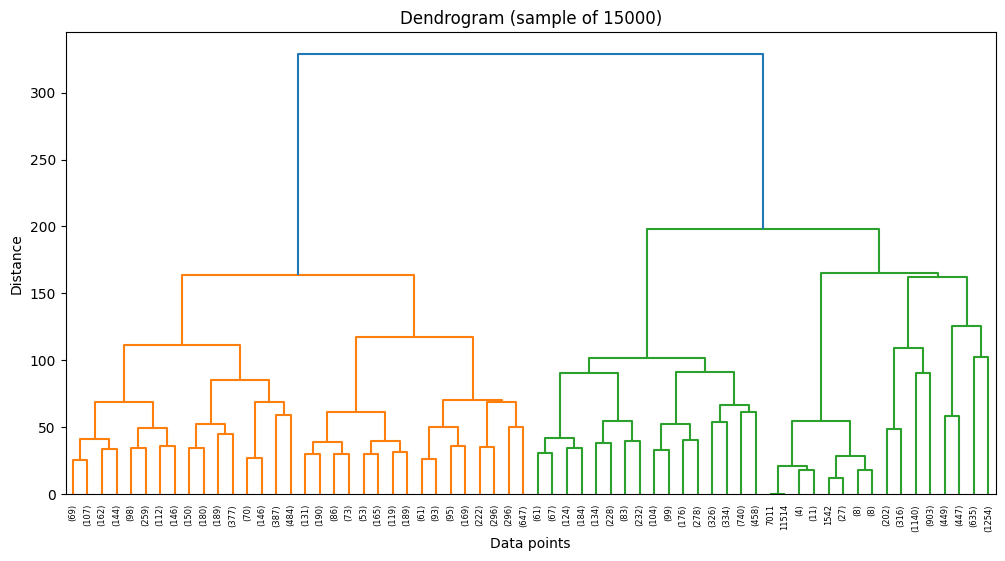

In [9]:
X_sample = resample(X_scaled, n_samples=15000, random_state=42)
linked = linkage(X_sample, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(linked, truncate_mode='level', p=5)
plt.title('Dendrogram (sample of 15000)')
plt.xlabel('Data points')
plt.ylabel('Distance')
plt.show()

### Dendrogram Analyzation
- It is clear from the picture that there is two major clusters. This is compatibel with the result we got from KMeans and other clustering methods that had the best scores for 2 clusters.
- There are also sublcusters in each of the two major clusters that are apart from each other. So performing sub-clustering can be useful. 
- The distance between clusters especially the major ones shows that the clusters have meaningful difference with each other and probably show two different sets of behavioral/mental traits in the dataset. 
- The dendrogram also shows that the data is not random in clustering and have a specific pattern.

## KMeans to find the 2 main clusters

In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

features = df.copy()
kmeans = KMeans(n_clusters=2, random_state=42, n_init='auto')
cluster_labels = kmeans.fit_predict(X_scaled)

df['main_cluster'] = cluster_labels
df['main_cluster'].value_counts()


sil = silhouette_score(X_scaled, cluster_labels)
db = davies_bouldin_score(X_scaled, cluster_labels)
ch = calinski_harabasz_score(X_scaled, cluster_labels)

print(f"Silhouette Score: {sil:.4f}")
print(f"Davies-Bouldin Index: {db:.4f}")
print(f"Calinski-Harabasz Score: {ch:.2f}")


Silhouette Score: 0.0884
Davies-Bouldin Index: 3.0201
Calinski-Harabasz Score: 10317.14


c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


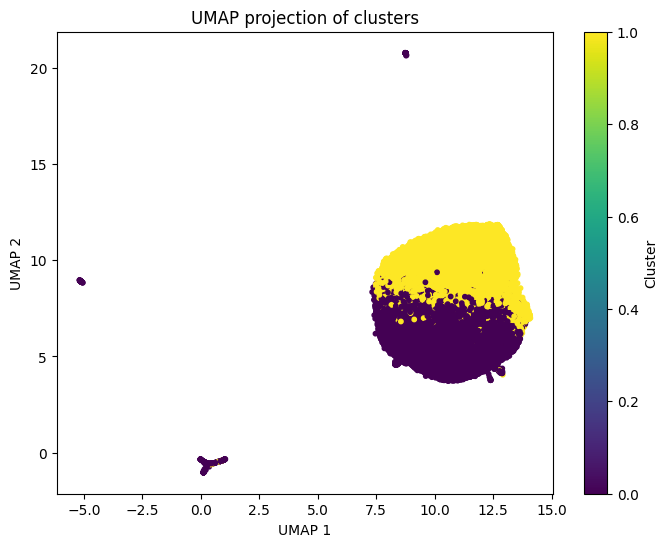

In [8]:
import umap
import matplotlib.pyplot as plt

reducer = umap.UMAP(random_state=42)
embedding = reducer.fit_transform(X_scaled)

plt.figure(figsize=(8,6))
plt.scatter(embedding[:,0], embedding[:,1], c=cluster_labels, cmap='viridis', s=10)
plt.title("UMAP projection of clusters")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.colorbar(label="Cluster")
plt.show()


### Output Analyzation
- We can see our two clusters in this picture, cluster 0 with purple color and cluster 1 with yellow color. 
- Most of the data is in a compact and large structure in the right. There seems to be some structure inside it that can show the sub-categories.
- We see that there's some groups of data in the bottom and left of the picture which can be outliers. 

### Outliers?
- In the code below we use DBSCAN to search for outliers.

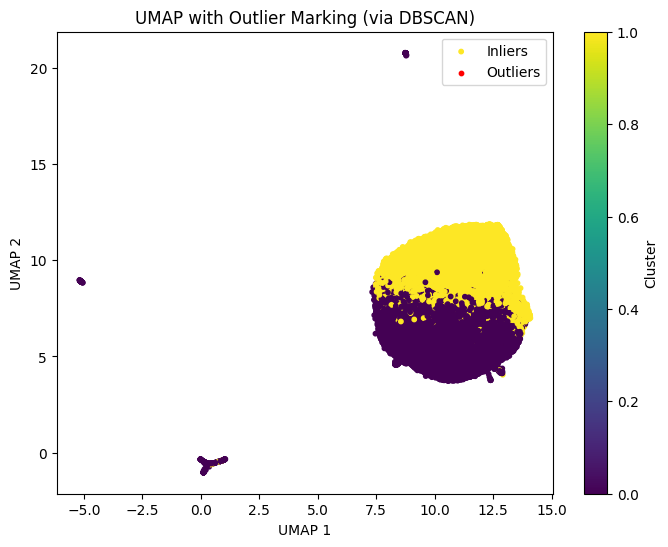

Number of outliers detected by DBSCAN: 0


In [10]:
import numpy as np
import umap
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.2, min_samples=8)
outlier_labels = dbscan.fit_predict(embedding)

is_outlier = outlier_labels == -1  

plt.figure(figsize=(8, 6))
plt.scatter(embedding[~is_outlier, 0], embedding[~is_outlier, 1],
            c=cluster_labels[~is_outlier], cmap='viridis', s=10, label="Inliers")
plt.scatter(embedding[is_outlier, 0], embedding[is_outlier, 1],
            color='red', s=10, label="Outliers")
plt.title("UMAP with Outlier Marking (via DBSCAN)")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.legend()
plt.colorbar(label="Cluster")
plt.show()

print("Number of outliers detected by DBSCAN:", np.sum(is_outlier))


## Sub-clustering 

#### KMeans vs Agglo

In [29]:
import numpy as np
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

# evaluation function
def evaluate_clustering(X, labels, model_name, k):
    print(f"--- {model_name} (k={k}) ---")
    print("Silhouette Score:", format(silhouette_score(X, labels), '.4f'))
    print("Calinski-Harabasz Score:", format(calinski_harabasz_score(X, labels), '.4f'))
    print("Davies-Bouldin Index:", format(davies_bouldin_score(X, labels), '.4f'))

    # number of data points in each cluster
    unique, counts = np.unique(labels, return_counts=True)  
    print("Cluster sizes:")
    for cluster_id, count in zip(unique, counts):
        print(f"  Cluster {cluster_id}: {count} data points")
    print()

# Plotting the UMAP function
def plot_umap(X, labels, model_name, k):
    reducer = umap.UMAP(n_components=2, random_state=42)
    X_umap = reducer.fit_transform(X)
    
    plt.figure(figsize=(6, 5))
    sns.scatterplot(x=X_umap[:, 0], y=X_umap[:, 1], hue=labels, palette='tab10', s=8, linewidth=0)
    plt.title(f'{model_name} (k={k})')
    plt.xlabel('UMAP-1')
    plt.ylabel('UMAP-2')
    plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

In [23]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.neighbors import KNeighborsClassifier

# extracting cluster 0 data, scaling and PCA

cluster_0_data = df[df['main_cluster'] == 0].copy()

scaler = StandardScaler()
X_cluster_0_scaled = scaler.fit_transform(cluster_0_data.drop(columns=['main_cluster']))

pca = PCA(n_components=40, random_state=42)
X_pca = pca.fit_transform(X_cluster_0_scaled)

### Cluster 0


==================== k = 2 ====================

--- KMeans (k=2) ---
Silhouette Score: 0.0755
Calinski-Harabasz Score: 4098.0233
Davies-Bouldin Index: 3.3772
Cluster sizes:
  Cluster 0: 21357 data points
  Cluster 1: 29768 data points



c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


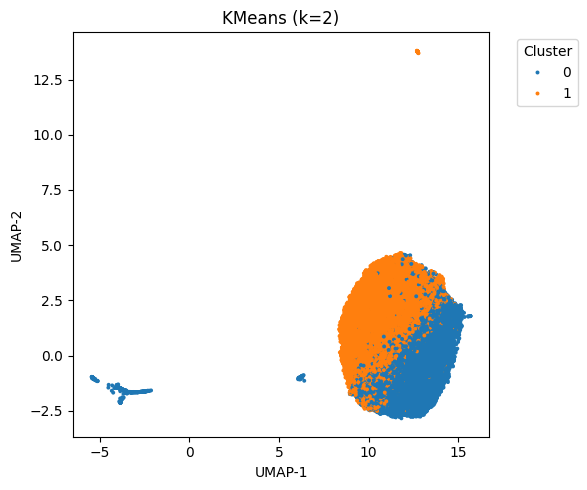

--- Agglomerative+KNN (k=2) ---
Silhouette Score: 0.5156
Calinski-Harabasz Score: 3440.1171
Davies-Bouldin Index: 0.6906
Cluster sizes:
  Cluster 0: 50598 data points
  Cluster 1: 527 data points



c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


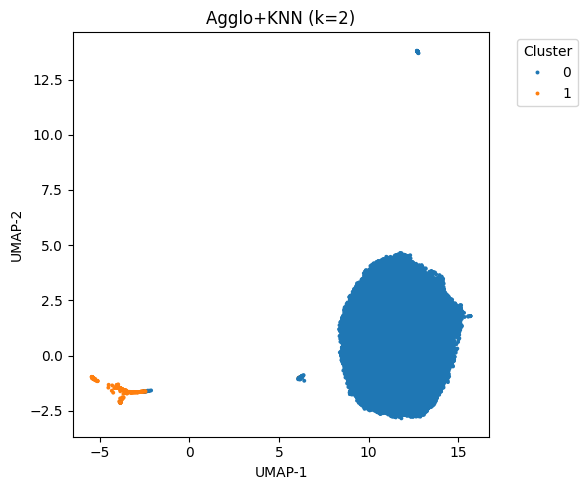


==================== k = 3 ====================

--- KMeans (k=3) ---
Silhouette Score: 0.0608
Calinski-Harabasz Score: 3205.7739
Davies-Bouldin Index: 3.1993
Cluster sizes:
  Cluster 0: 16707 data points
  Cluster 1: 22597 data points
  Cluster 2: 11821 data points



c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


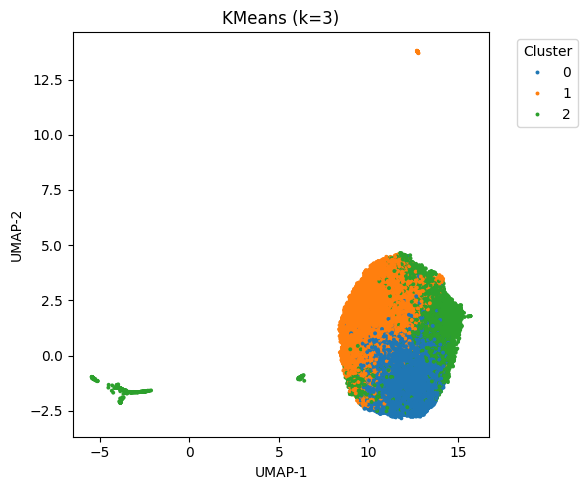

--- Agglomerative+KNN (k=3) ---
Silhouette Score: 0.0516
Calinski-Harabasz Score: 2979.0314
Davies-Bouldin Index: 2.9941
Cluster sizes:
  Cluster 0: 35253 data points
  Cluster 1: 530 data points
  Cluster 2: 15342 data points



c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


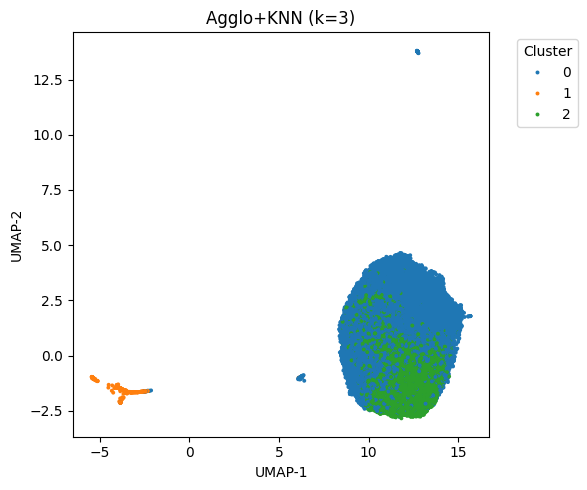


==================== k = 4 ====================

--- KMeans (k=4) ---
Silhouette Score: 0.0512
Calinski-Harabasz Score: 2820.3461
Davies-Bouldin Index: 3.2335
Cluster sizes:
  Cluster 0: 10625 data points
  Cluster 1: 16738 data points
  Cluster 2: 14325 data points
  Cluster 3: 9437 data points



c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


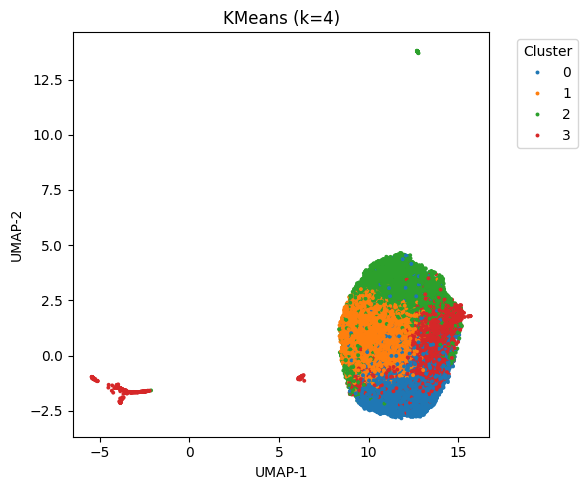

--- Agglomerative+KNN (k=4) ---
Silhouette Score: 0.0388
Calinski-Harabasz Score: 2532.4694
Davies-Bouldin Index: 3.0904
Cluster sizes:
  Cluster 0: 26804 data points
  Cluster 1: 6051 data points
  Cluster 2: 17740 data points
  Cluster 3: 530 data points



c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


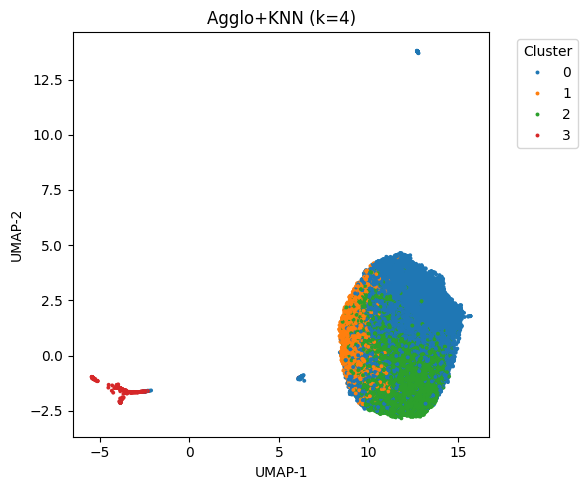


==================== k = 5 ====================

--- KMeans (k=5) ---
Silhouette Score: 0.0570
Calinski-Harabasz Score: 3094.8809
Davies-Bouldin Index: 2.6456
Cluster sizes:
  Cluster 0: 9852 data points
  Cluster 1: 14351 data points
  Cluster 2: 13049 data points
  Cluster 3: 528 data points
  Cluster 4: 13345 data points



c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


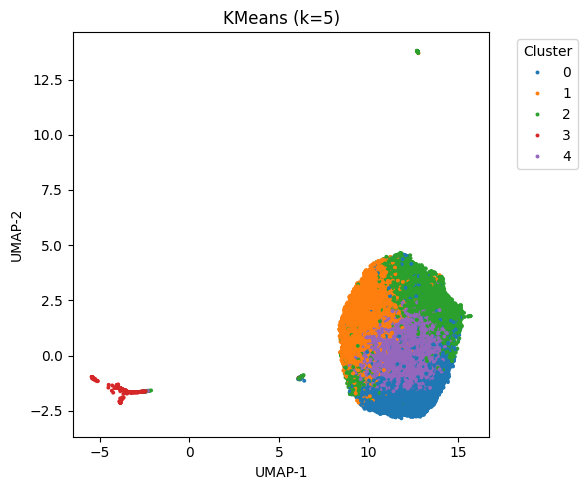

--- Agglomerative+KNN (k=5) ---
Silhouette Score: 0.0315
Calinski-Harabasz Score: 2258.8262
Davies-Bouldin Index: 3.2911
Cluster sizes:
  Cluster 0: 21969 data points
  Cluster 1: 6532 data points
  Cluster 2: 14598 data points
  Cluster 3: 532 data points
  Cluster 4: 7494 data points



c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


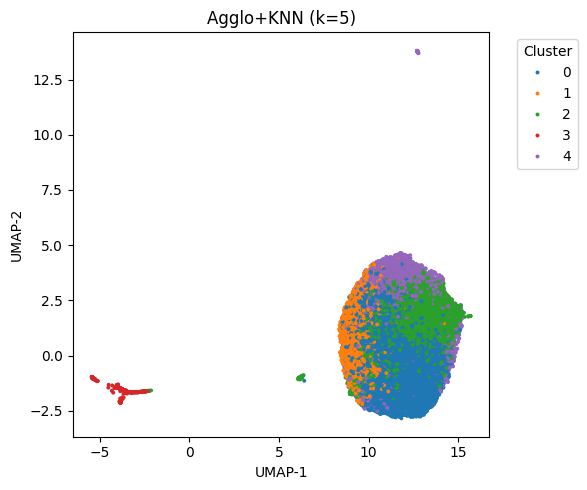


==================== k = 6 ====================

--- KMeans (k=6) ---
Silhouette Score: 0.0531
Calinski-Harabasz Score: 2795.3242
Davies-Bouldin Index: 2.6994
Cluster sizes:
  Cluster 0: 7314 data points
  Cluster 1: 11119 data points
  Cluster 2: 10378 data points
  Cluster 3: 10321 data points
  Cluster 4: 11469 data points
  Cluster 5: 524 data points



c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


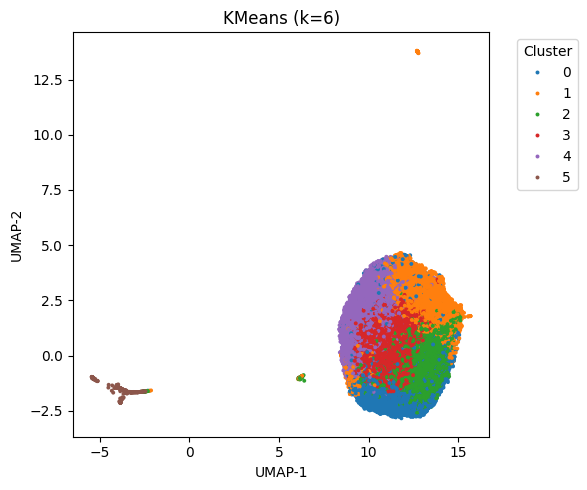

--- Agglomerative+KNN (k=6) ---
Silhouette Score: 0.0302
Calinski-Harabasz Score: 2065.5254
Davies-Bouldin Index: 3.2994
Cluster sizes:
  Cluster 0: 7794 data points
  Cluster 1: 13955 data points
  Cluster 2: 16305 data points
  Cluster 3: 532 data points
  Cluster 4: 7679 data points
  Cluster 5: 4860 data points



c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


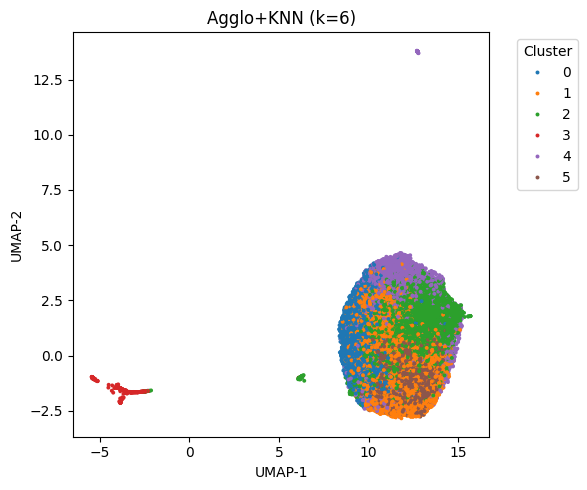

In [30]:
# running KMeans and Agglomerative Clustering on PCA data

sample_size = 5000
k_range = range(2, 7)

for k in k_range:
    print(f"\n==================== k = {k} ====================\n")

    # KMeans
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans_labels = kmeans.fit_predict(X_pca)
    evaluate_clustering(X_pca, kmeans_labels, "KMeans", k)
    plot_umap(X_pca, kmeans_labels, "KMeans", k)


    # Agglomerative (on sample + KNN)
    np.random.seed(42)
    sample_indices = np.random.choice(len(X_pca), size=sample_size, replace=False)
    X_sample = X_pca[sample_indices]

    agglo = AgglomerativeClustering(n_clusters=k, linkage='ward')
    agglo_labels_sample = agglo.fit_predict(X_sample)

    knn = KNeighborsClassifier(n_neighbors=10)
    knn.fit(X_sample, agglo_labels_sample)

    agglo_labels_full = knn.predict(X_pca)

    evaluate_clustering(X_pca, agglo_labels_full, "Agglomerative+KNN", k)
    plot_umap(X_pca, agglo_labels_full, "Agglo+KNN", k)
    

### Cluster 1

In [18]:
# extracting cluster 1 data, scaling and PCA

cluster_1_data = df[df['main_cluster'] == 1].copy()

X_cluster_1_scaled = scaler.fit_transform(cluster_1_data.drop(columns=['main_cluster']))

pca = PCA(n_components=40, random_state=42)
X_pca_1 = pca.fit_transform(X_cluster_1_scaled)


==================== k = 2 ====================

--- KMeans (k=2) ---
Silhouette Score: 0.0720
Calinski-Harabasz Score: 3976.0408
Davies-Bouldin Index: 3.4185
Cluster sizes:
  Cluster 0: 22564 data points
  Cluster 1: 26311 data points



c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


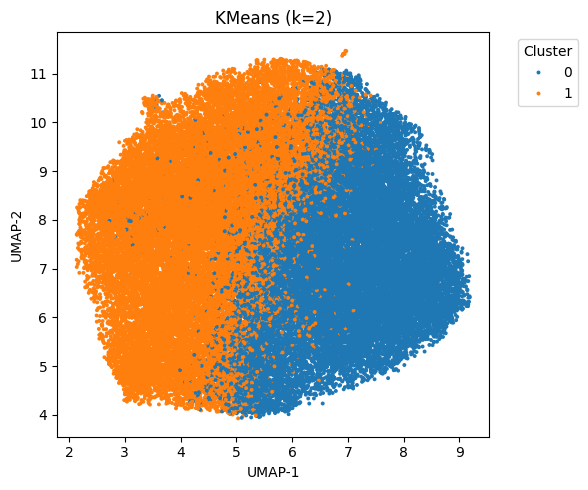

--- Agglomerative+KNN (k=2) ---
Silhouette Score: 0.0610
Calinski-Harabasz Score: 2032.8866
Davies-Bouldin Index: 3.0307
Cluster sizes:
  Cluster 0: 42995 data points
  Cluster 1: 5880 data points



c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


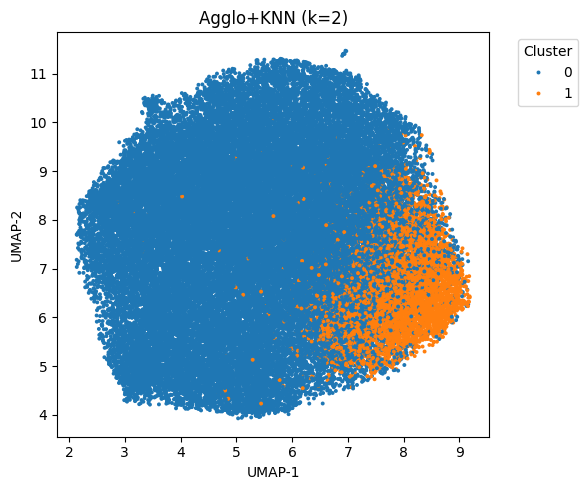


==================== k = 3 ====================

--- KMeans (k=3) ---
Silhouette Score: 0.0623
Calinski-Harabasz Score: 3207.9436
Davies-Bouldin Index: 3.2699
Cluster sizes:
  Cluster 0: 16688 data points
  Cluster 1: 13681 data points
  Cluster 2: 18506 data points



c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


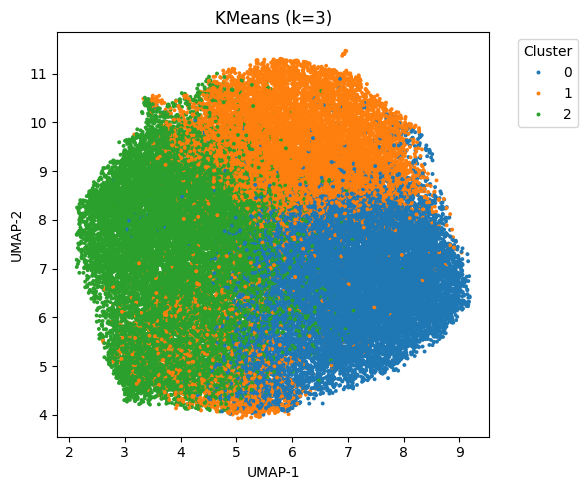

--- Agglomerative+KNN (k=3) ---
Silhouette Score: 0.0297
Calinski-Harabasz Score: 2137.5481
Davies-Bouldin Index: 3.3669
Cluster sizes:
  Cluster 0: 33303 data points
  Cluster 1: 7338 data points
  Cluster 2: 8234 data points



c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


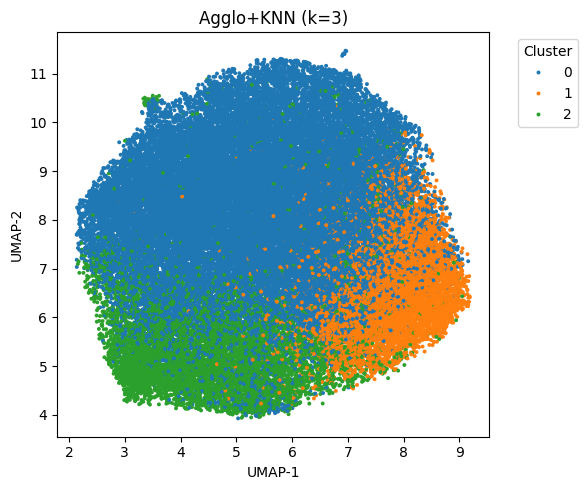


==================== k = 4 ====================

--- KMeans (k=4) ---
Silhouette Score: 0.0597
Calinski-Harabasz Score: 2870.3147
Davies-Bouldin Index: 2.9956
Cluster sizes:
  Cluster 0: 14309 data points
  Cluster 1: 14116 data points
  Cluster 2: 9733 data points
  Cluster 3: 10717 data points



c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


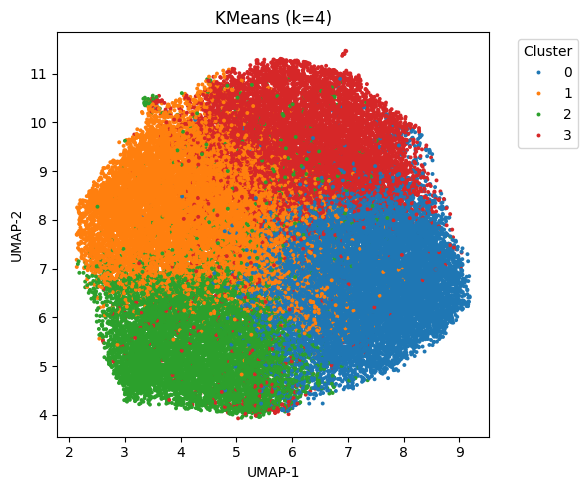

--- Agglomerative+KNN (k=4) ---
Silhouette Score: 0.0408
Calinski-Harabasz Score: 2012.7200
Davies-Bouldin Index: 3.4397
Cluster sizes:
  Cluster 0: 26217 data points
  Cluster 1: 5302 data points
  Cluster 2: 9279 data points
  Cluster 3: 8077 data points



c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


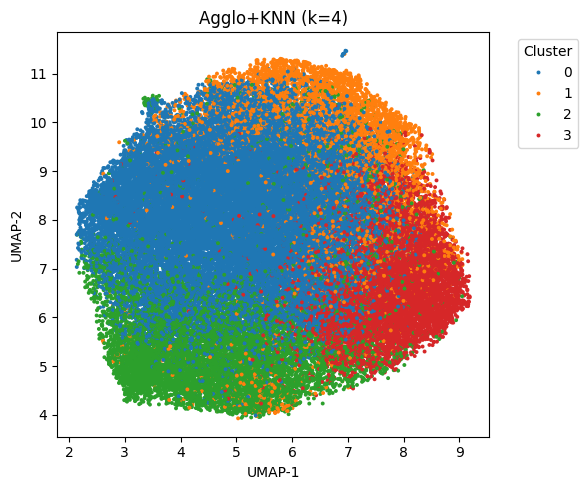


==================== k = 5 ====================

--- KMeans (k=5) ---
Silhouette Score: 0.0572
Calinski-Harabasz Score: 2544.7242
Davies-Bouldin Index: 2.9849
Cluster sizes:
  Cluster 0: 8583 data points
  Cluster 1: 9862 data points
  Cluster 2: 10631 data points
  Cluster 3: 7846 data points
  Cluster 4: 11953 data points



c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


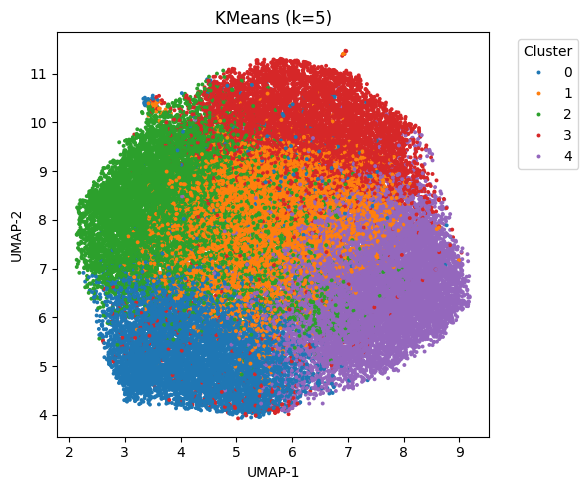

--- Agglomerative+KNN (k=5) ---
Silhouette Score: 0.0344
Calinski-Harabasz Score: 1823.9395
Davies-Bouldin Index: 3.6830
Cluster sizes:
  Cluster 0: 6623 data points
  Cluster 1: 18983 data points
  Cluster 2: 10090 data points
  Cluster 3: 8662 data points
  Cluster 4: 4517 data points



c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


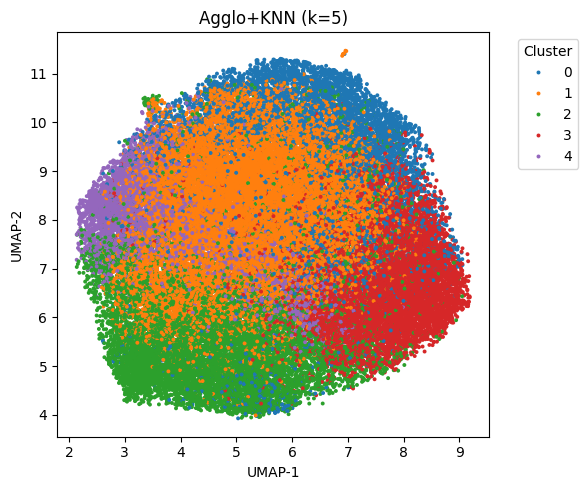


==================== k = 6 ====================

--- KMeans (k=6) ---
Silhouette Score: 0.0532
Calinski-Harabasz Score: 2296.0574
Davies-Bouldin Index: 3.0043
Cluster sizes:
  Cluster 0: 9351 data points
  Cluster 1: 8868 data points
  Cluster 2: 9247 data points
  Cluster 3: 5636 data points
  Cluster 4: 8124 data points
  Cluster 5: 7649 data points



c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


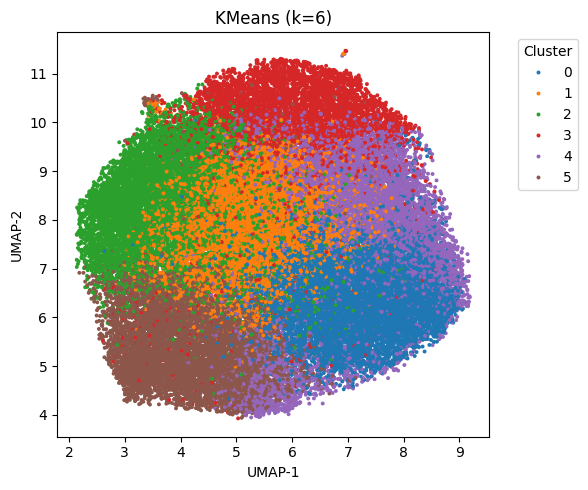

--- Agglomerative+KNN (k=6) ---
Silhouette Score: 0.0329
Calinski-Harabasz Score: 1569.6423
Davies-Bouldin Index: 3.3521
Cluster sizes:
  Cluster 0: 3565 data points
  Cluster 1: 19730 data points
  Cluster 2: 10374 data points
  Cluster 3: 9013 data points
  Cluster 4: 4578 data points
  Cluster 5: 1615 data points



c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


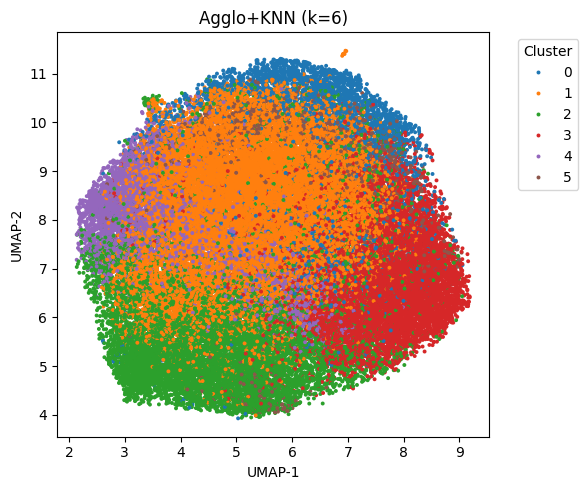

In [32]:
# running KMeans and Agglomerative Clustering on PCA data - cluster 1

sample_size = 5000
k_range = range(2, 7)

for k in k_range:
    print(f"\n==================== k = {k} ====================\n")

    # KMeans
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans_labels = kmeans.fit_predict(X_pca_1)
    evaluate_clustering(X_pca_1, kmeans_labels, "KMeans", k)
    plot_umap(X_pca_1, kmeans_labels, "KMeans", k)


    # Agglomerative (on sample + KNN)
    np.random.seed(42)
    sample_indices = np.random.choice(len(X_pca_1), size=sample_size, replace=False)
    X_sample = X_pca_1[sample_indices]

    agglo = AgglomerativeClustering(n_clusters=k, linkage='ward')
    agglo_labels_sample = agglo.fit_predict(X_sample)

    knn = KNeighborsClassifier(n_neighbors=10)
    knn.fit(X_sample, agglo_labels_sample)

    agglo_labels_full = knn.predict(X_pca_1)

    evaluate_clustering(X_pca_1, agglo_labels_full, "Agglomerative+KNN", k)
    plot_umap(X_pca_1, agglo_labels_full, "Agglo+KNN", k)
    

#### separate sub-clustering

In [14]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

cluster_0_data = df[df['main_cluster'] == 0].copy()

scaler = StandardScaler()
X_cluster_0_scaled = scaler.fit_transform(cluster_0_data.drop(columns=['main_cluster']))

sample_size = 5000
np.random.seed(42)
sample_indices = np.random.choice(len(X_cluster_0_scaled), size=sample_size, replace=False)
X_sample = X_cluster_0_scaled[sample_indices]

pca = PCA(n_components=40, random_state=42)
X_sample_pca = pca.fit_transform(X_sample)

agglo = AgglomerativeClustering(n_clusters=2, linkage='ward')
subcluster_labels_sample = agglo.fit_predict(X_sample_pca)

knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(X_sample_pca, subcluster_labels_sample)

X_cluster_0_pca_full = pca.transform(X_cluster_0_scaled)
subcluster_labels_full = knn.predict(X_cluster_0_pca_full)

cluster_0_data['subcluster'] = subcluster_labels_full

print(cluster_0_data['subcluster'].value_counts())


subcluster
0    50610
1      515
Name: count, dtype: int64


### subcluster 0.1 ✅

c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


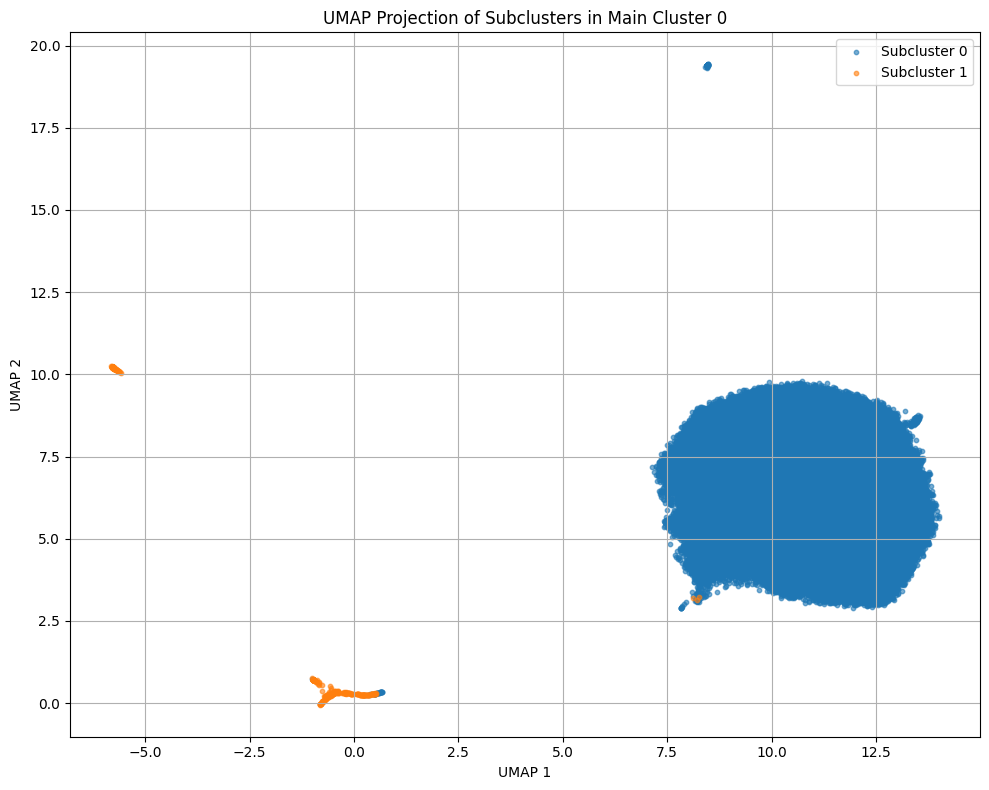

In [15]:
import umap.umap_ as umap
import matplotlib.pyplot as plt

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
embedding = reducer.fit_transform(X_cluster_0_scaled)

cluster_0_data['umap_x'] = embedding[:, 0]
cluster_0_data['umap_y'] = embedding[:, 1]

plt.figure(figsize=(10, 8))
colors = ['#1f77b4', '#ff7f0e'] 
for label in sorted(cluster_0_data['subcluster'].unique()):
    subset = cluster_0_data[cluster_0_data['subcluster'] == label]
    plt.scatter(subset['umap_x'], subset['umap_y'], 
                label=f'Subcluster {label}', 
                alpha=0.6, s=10, c=colors[label])

plt.title('UMAP Projection of Subclusters in Main Cluster 0')
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


## continuing subclustering with subcluster 0.0

### Agglo

In [21]:
subcluster_0_data = cluster_0_data[cluster_0_data['subcluster'] == 0].copy()

X_sub0 = subcluster_0_data.drop(columns=['main_cluster', 'subcluster'])

X_sub0_scaled = scaler.fit_transform(X_sub0)

import numpy as np

sample_size = 5000
np.random.seed(42)
sample_indices = np.random.choice(len(X_sub0_scaled), size=sample_size, replace=False)
X_sub0_sample = X_sub0_scaled[sample_indices]

from sklearn.decomposition import PCA

pca = PCA(n_components=40, random_state=42)
X_sub0_sample_pca = pca.fit_transform(X_sub0_sample)

from sklearn.cluster import AgglomerativeClustering

agglo = AgglomerativeClustering(n_clusters=2, linkage='ward')
subsubcluster_labels_sample = agglo.fit_predict(X_sub0_sample_pca)

from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(X_sub0_sample_pca, subsubcluster_labels_sample)

X_sub0_pca_full = pca.transform(X_sub0_scaled)
subsubcluster_labels_full = knn.predict(X_sub0_pca_full)

subcluster_0_data['subcluster_lvl2'] = subsubcluster_labels_full

print(subcluster_0_data['subcluster_lvl2'].value_counts())

X_eval = X_sub0_pca_full 
labels = subsubcluster_labels_full

sil_score = silhouette_score(X_eval, labels)
ch_score = calinski_harabasz_score(X_eval, labels)
db_score = davies_bouldin_score(X_eval, labels)

print(f"Silhouette Score: {sil_score:.4f}")
print(f"Calinski-Harabasz Score: {ch_score:.4f}")
print(f"Davies-Bouldin Index: {db_score:.4f}")

subcluster_lvl2
0    40676
1     9934
Name: count, dtype: int64
Silhouette Score: 0.0830
Calinski-Harabasz Score: 3006.5080
Davies-Bouldin Index: 3.1952


c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


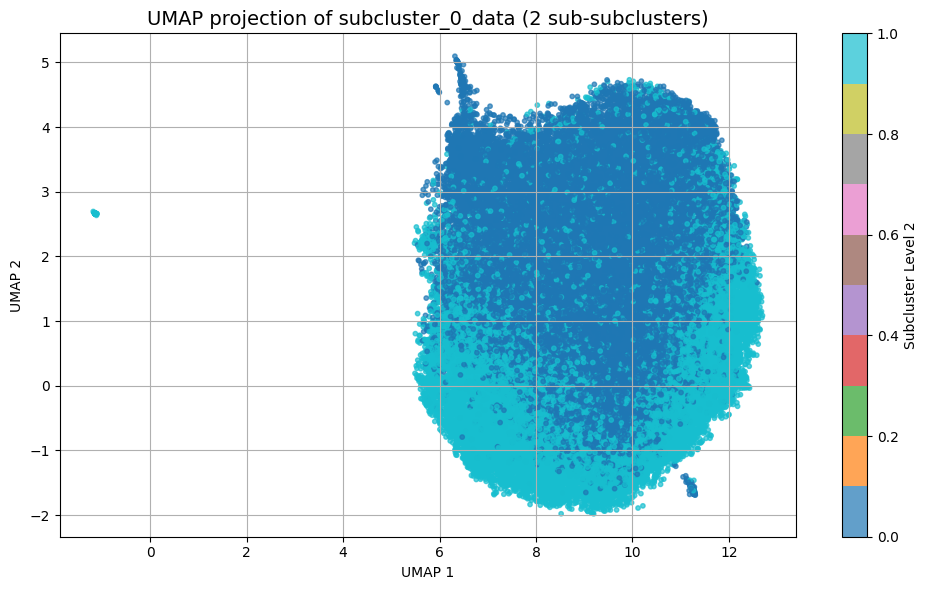

In [36]:
import umap.umap_ as umap
import matplotlib.pyplot as plt

umap_model = umap.UMAP(n_components=2, random_state=42)
X_sub0_umap = umap_model.fit_transform(X_sub0_scaled)

plt.figure(figsize=(10, 6))
plt.scatter(
    X_sub0_umap[:, 0],
    X_sub0_umap[:, 1],
    c=subcluster_0_data['subcluster_lvl2'],
    cmap='tab10',
    s=10,
    alpha=0.7
)
plt.title('UMAP projection of subcluster_0_data (2 sub-subclusters)', fontsize=14)
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.colorbar(label='Subcluster Level 2')
plt.grid(True)
plt.tight_layout()
plt.show()


### ‌Kmeans

In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

subcluster_0_data = cluster_0_data[cluster_0_data['subcluster'] == 0].copy()

X_sub0 = subcluster_0_data.drop(columns=['main_cluster', 'subcluster'])

scaler = StandardScaler()
X_sub0_scaled = scaler.fit_transform(X_sub0)

pca = PCA(n_components=40, random_state=42)
X_sub0_pca = pca.fit_transform(X_sub0_scaled)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_sub0_pca)

subcluster_0_data['subcluster_lvl2'] = labels

print(subcluster_0_data['subcluster_lvl2'].value_counts())

sil_score = silhouette_score(X_sub0_pca, labels)
ch_score = calinski_harabasz_score(X_sub0_pca, labels)
db_score = davies_bouldin_score(X_sub0_pca, labels)

print(f"Silhouette Score: {sil_score:.4f}")
print(f"Calinski-Harabasz Score: {ch_score:.2f}")
print(f"Davies-Bouldin Index: {db_score:.4f}")


subcluster_lvl2
2    14256
3    13180
1    13163
0    10011
Name: count, dtype: int64
Silhouette Score: 0.0592
Calinski-Harabasz Score: 3244.60
Davies-Bouldin Index: 2.9605


c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


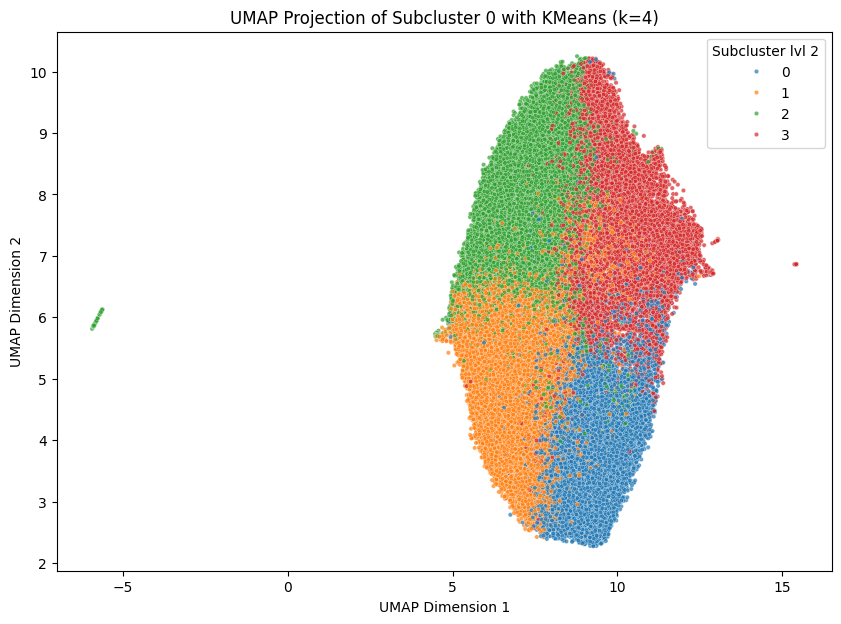

In [25]:
import umap
import matplotlib.pyplot as plt
import seaborn as sns

reducer = umap.UMAP(random_state=42)
embedding = reducer.fit_transform(X_sub0_scaled)  

plt.figure(figsize=(10, 7))
palette = sns.color_palette("tab10", n_colors=4)  

sns.scatterplot(
    x=embedding[:, 0], y=embedding[:, 1],
    hue=labels,
    palette=palette,
    legend='full',
    s=10,
    alpha=0.7
)
plt.title("UMAP Projection of Subcluster 0 with KMeans (k=4)")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
plt.legend(title='Subcluster lvl 2')
plt.show()


In [59]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

print(f"{'K':<5}{'Silhouette':<15}{'Davies-Bouldin':<20}{'Calinski-Harabasz'}")
for n_clusters in range(2, 7):
    agglo = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
    labels = agglo.fit_predict(X_sub0_sample_pca)
    
    sil_score = silhouette_score(X_sub0_sample_pca, labels)
    db_score = davies_bouldin_score(X_sub0_sample_pca, labels)
    ch_score = calinski_harabasz_score(X_sub0_sample_pca, labels)
    
    print(f"{n_clusters:<5}{sil_score:<15.4f}{db_score:<20.4f}{ch_score:.4f}")


K    Silhouette     Davies-Bouldin      Calinski-Harabasz
2    0.0681         3.6092              297.3378
3    0.0473         3.5463              275.6056
4    0.0446         3.4317              227.2398
5    0.0284         3.7819              200.4657
6    0.0252         3.7597              181.5608


- We see that k=2 has the best scores so the number of clusters we chose in the previous cells was a good choice.

## Continuing with subcluster 0.0.0

In [37]:
subsubcluster_0_data = subcluster_0_data[subcluster_0_data['subcluster_lvl2'] == 0].copy()

X_subsub0 = subsubcluster_0_data.drop(columns=['main_cluster', 'subcluster', 'subcluster_lvl2'])

scaler = StandardScaler()
X_subsub0_scaled = scaler.fit_transform(X_subsub0)

sample_size = 5000
np.random.seed(42)
sample_indices = np.random.choice(len(X_subsub0_scaled), size=sample_size, replace=False)
X_subsub0_sample = X_subsub0_scaled[sample_indices]

# PCA
from sklearn.decomposition import PCA

pca = PCA(n_components=40, random_state=42)
X_subsub0_sample_pca = pca.fit_transform(X_subsub0_sample)

from sklearn.cluster import AgglomerativeClustering

agglo = AgglomerativeClustering(n_clusters=3, linkage='ward')
subsubsubcluster_labels_sample = agglo.fit_predict(X_subsub0_sample_pca)

from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(X_subsub0_sample_pca, subsubsubcluster_labels_sample)

X_subsub0_pca_full = pca.transform(X_subsub0_scaled)
subsubsubcluster_labels_full = knn.predict(X_subsub0_pca_full)

subsubcluster_0_data['subcluster_lvl3'] = subsubsubcluster_labels_full

print(subsubcluster_0_data['subcluster_lvl3'].value_counts())

X_eval = X_subsub0_pca_full  
labels = subsubsubcluster_labels_full

sil_score = silhouette_score(X_eval, labels)
ch_score = calinski_harabasz_score(X_eval, labels)
db_score = davies_bouldin_score(X_eval, labels)

print(f"Silhouette Score: {sil_score:.4f}")
print(f"Calinski-Harabasz Score: {ch_score:.4f}")
print(f"Davies-Bouldin Index: {db_score:.4f}")



subcluster_lvl3
1    14020
0    11425
2     5591
Name: count, dtype: int64
Silhouette Score: 0.0511
Calinski-Harabasz Score: 1772.3144
Davies-Bouldin Index: 3.3819


c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\uni-generall\term8\پروژه\project\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


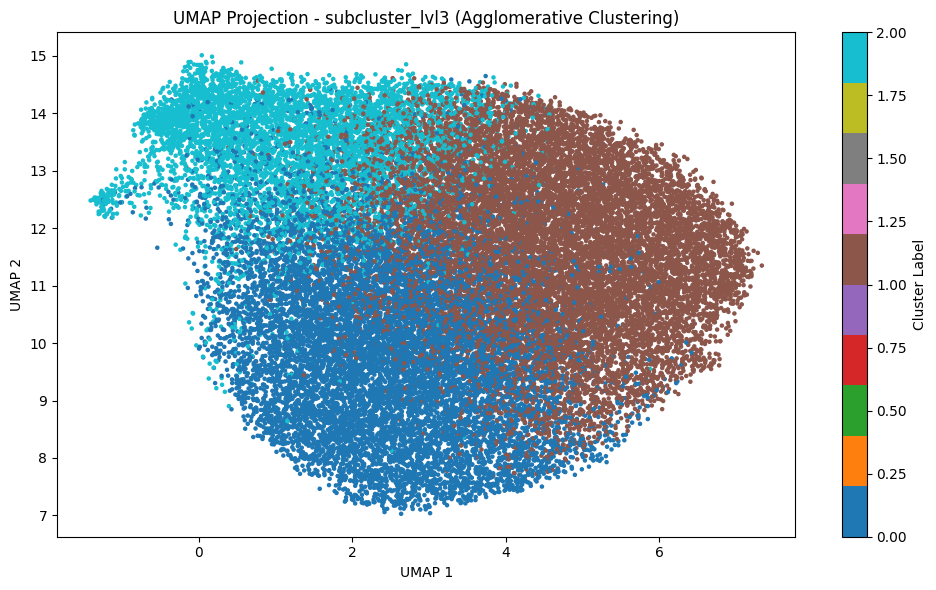

In [38]:
import umap.umap_ as umap
import matplotlib.pyplot as plt

X_umap_input = subsubcluster_0_data.drop(columns=['main_cluster', 'subcluster', 'subcluster_lvl2', 'subcluster_lvl3'])
X_umap_scaled = scaler.fit_transform(X_umap_input)  # مجدد مقیاس‌بندی برای UMAP (ضروری نیست اگر همون داده قبلیه، ولی بهتره)

# UMAP
umap_model = umap.UMAP(n_neighbors=50, min_dist=0.3, random_state=42)
X_umap = umap_model.fit_transform(X_umap_scaled)

plt.figure(figsize=(10, 6))
plt.scatter(X_umap[:, 0], X_umap[:, 1], c=subsubcluster_0_data['subcluster_lvl3'], cmap='tab10', s=5)
plt.title('UMAP Projection - subcluster_lvl3 (Agglomerative Clustering)')
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.colorbar(label='Cluster Label')
plt.tight_layout()
plt.show()


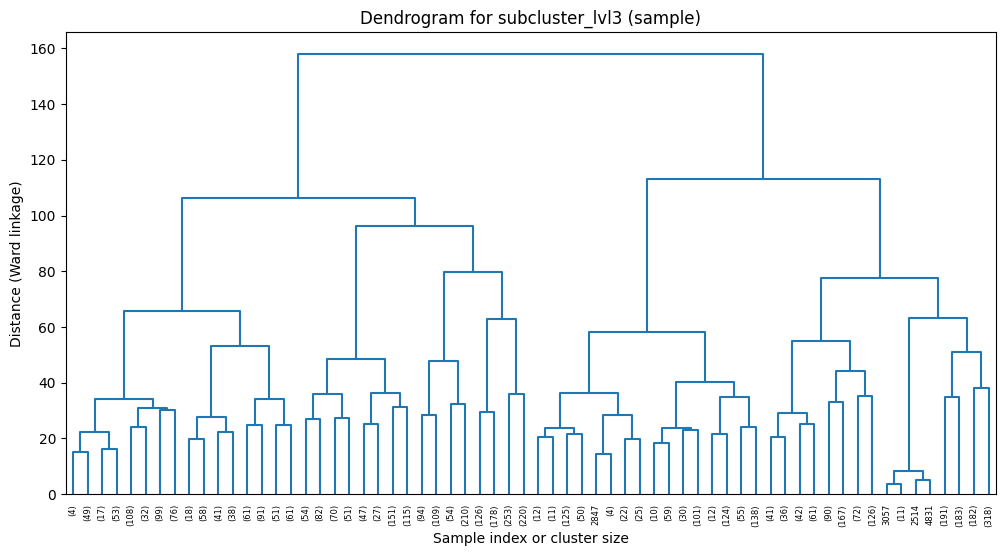

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

Z = linkage(X_subsub0_sample_pca, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='level', p=5, color_threshold=0)
plt.title('Dendrogram for subcluster_lvl3 (sample)')
plt.xlabel('Sample index or cluster size')
plt.ylabel('Distance (Ward linkage)')
plt.show()